# Лабораторная работа 1. Регрессия: качество вина

Предсказываем оценку `quality` по химическому составу красного и белого вина (Wine Quality, UCI).

Нужно пройти путь от разбора данных и константного baseline до линейной регрессии, случайного леса и градиентного бустинга. Метрики — RMSE и MAE. Порог качества из задания — RMSE < 0.70 на одной отложенной тестовой выборке.

Ниже одно и то же разбиение для всех моделей. Параметры выбираются кросс-валидацией на обучающей части. Тест считается один раз и в подбор не входит.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

plt.rcParams["font.family"] = "DejaVu Sans"
sns.set(style="darkgrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_DIR = Path.cwd()
if not (DATA_DIR / "winequality-red.csv").exists():
    raise FileNotFoundError(
        "Положите winequality-red.csv и winequality-white.csv рядом с ноутбуком и запустите его из этой папки."
    )

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

## Данные

Берём оба файла UCI и добавляем признак `color`. Оценка `quality` — целое число, по смыслу медиана оценок дегустаторов, а не результат прибора. Пропусков в этих файлах нет. Признаки лежат в разных единицах: диоксид серы — десятки и сотни мг/л, хлориды и плотность — доли.

In [2]:
red = pd.read_csv(DATA_DIR / "winequality-red.csv", sep=";")
white = pd.read_csv(DATA_DIR / "winequality-white.csv", sep=";")
red["color"] = "red"
white["color"] = "white"
raw = pd.concat([red, white], ignore_index=True)

feature_cols = [c for c in raw.columns if c != "quality"]
conflict = raw.groupby(feature_cols, dropna=False)["quality"].nunique()
print("Строк в склейке:", raw.shape[0])
print("Полных дубликатов:", int(raw.duplicated().sum()))
print("Одинаковый состав и разный quality:", int((conflict > 1).sum()))
print("Пропусков:", int(raw.isna().sum().sum()))

data = raw.drop_duplicates().reset_index(drop=True)
print("После удаления дубликатов:", data.shape)
print(data["color"].value_counts())
print(data.groupby("color")["quality"].mean().round(3))
data.describe().T.round(3)

Строк в склейке: 6497
Полных дубликатов: 1177
Одинаковый состав и разный quality: 0
Пропусков: 0
После удаления дубликатов: (5320, 13)
color
white    3961
red      1359
Name: count, dtype: int64
color
red      5.623
white    5.855
Name: quality, dtype: float64


,count,mean,std,min,25%,50%,75%,max
fixed acidity,5320.0,7.215,1.320,3.800,6.400,7.000,7.700,15.900
volatile acidity,5320.0,0.344,0.168,0.080,0.230,0.300,0.410,1.580
citric acid,5320.0,0.318,0.147,0.000,0.240,0.310,0.400,1.660
residual sugar,5320.0,5.048,4.500,0.600,1.800,2.700,7.500,65.800
chlorides,5320.0,0.057,0.037,0.009,0.038,0.047,0.066,0.611
free sulfur dioxide,5320.0,30.037,17.805,1.000,16.000,28.000,41.000,289.000
total sulfur dioxide,5320.0,114.109,56.774,6.000,74.000,116.000,153.250,440.000
density,5320.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,5320.0,3.225,0.160,2.720,3.110,3.210,3.330,4.010
sulphates,5320.0,0.533,0.150,0.220,0.430,0.510,0.600,2.000


Дубликаты удалены до разбиения: 1177 повторных строк из 6497. Одинаковых описаний с разным `quality` нет, так что это копии, а не противоречивые ответы.

Если копии оставить, случайное разбиение кладёт одну и ту же строку и в train, и в test. Лес такую строку запоминает, и тестовый RMSE становится оптимистичным: он частично измеряет память, а не прогноз нового вина. После очистки пересечения по составу быть не должно, это проверяется сразу после split.

Красных вин 1359, белых 3961. Средняя оценка белых чуть выше (5.86 против 5.62). Разрыв небольшой: цвет сам по себе качество не объясняет, но составы двух групп разные, поэтому `color` в признаках остаётся.

Масштаб признаков разный. Для обычной линейной регрессии без штрафа масштаб не меняет прогнозы, но делает коэффициенты несравнимыми. Для Ridge это уже влияет на сам прогноз: штраф одинаково давит все коэффициенты, и признак с маленькими числами получает несправедливо большой вес. Деревья к монотонному масштабу нечувствительны.

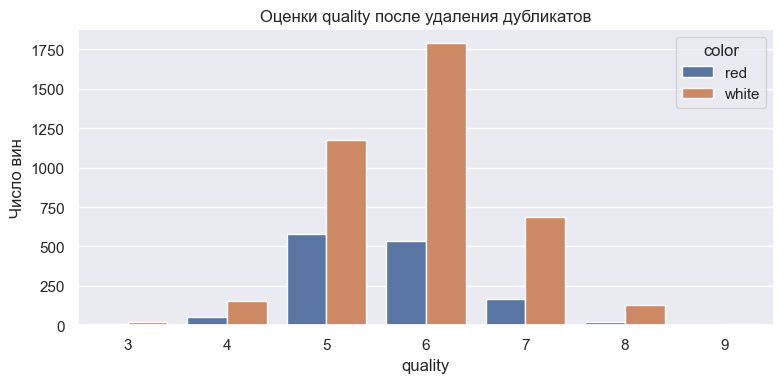

quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64


In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=data, x="quality", hue="color", ax=ax)
ax.set_title("Оценки quality после удаления дубликатов")
ax.set_xlabel("quality")
ax.set_ylabel("Число вин")
plt.tight_layout()
plt.show()

print(data["quality"].value_counts().sort_index())

Почти вся масса оценок — 5, 6 и 7. Троек 30, девяток 5. Модель, которая минимизирует квадрат ошибки, будет тянуть прогноз к частым оценкам. Редкие края она систематически промахивает, и эти промахи сильно видны в RMSE: ошибка на 3 балла входит в сумму квадратов как 9.

## Разбиение

Тест нужен только для итоговой оценки. Всё, что выбирается — обрезка хвостов, коэффициент Ridge, глубина леса, число деревьев бустинга — считается на обучающей части, по 5-fold кросс-валидации.

Разбиение стратифицировано по `quality`. Оценки 3 и 9 слишком редкие: без стратификации все девятки могут уехать в одну часть, и сравнивать модели на краях будет не на чем. Доля теста 20%: 4256 объектов на обучение и 1064 на проверку. `random_state=42` фиксирует состав выборок.

Перемешивание включено специально. Файл сложен как «сначала всё красное, потом всё белое». Без shuffle хвост теста был бы почти целиком белым вином, и модели сравнивались бы не на той смеси, на которой учились.

Многократная оценка на одном и том же тесте ломает эксперимент. Каждый просмотр, после которого меняется модель или параметр, подстраивает решение под шум именно этой выборки. Тест перестаёт оценивать новые данные и становится второй обучающей выборкой. RMSE в таблице тогда меньше той ошибки, которая будет на винах, не участвовавших в решениях. Поэтому здесь нет цикла «посмотрел тест — поменял параметр — посмотрел снова».

In [4]:
y = data["quality"]
X = data.drop(columns=["quality"])
assert "quality" not in X.columns

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

train_keys = set(map(tuple, X_train.to_numpy()))
copied = sum(tuple(row) in train_keys for row in X_test.to_numpy())
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Совпадающих строк состава между train и test:", copied)
print("Доли quality, train:")
print((y_train.value_counts(normalize=True).sort_index() * 100).round(1))
print("Доли quality, test:")
print((y_test.value_counts(normalize=True).sort_index() * 100).round(1))

Train: (4256, 12) Test: (1064, 12)
Совпадающих строк состава между train и test: 0
Доли quality, train:
quality
3     0.6
4     3.9
5    32.9
6    43.7
7    16.1
8     2.8
9     0.1
Name: proportion, dtype: float64
Доли quality, test:
quality
3     0.6
4     3.9
5    32.9
6    43.7
7    16.1
8     2.8
9     0.1
Name: proportion, dtype: float64


Совпадающих строк между train и test нет. Доли оценок в обеих частях близки, включая редкие 3 и 9. Дальше любые графики, по которым принимается решение о модели, считаются на train. Полная таблица выше использовалась только чтобы описать файл: размер, пропуски, дубликаты, баланс цвета и оценок.

## Связи в обучающей выборке

alcohol                 0.469
citric acid             0.094
pH                      0.051
free sulfur dioxide     0.049
sulphates               0.045
total sulfur dioxide   -0.061
residual sugar         -0.065
fixed acidity          -0.080
chlorides              -0.201
volatile acidity       -0.256
density                -0.328
Name: quality, dtype: float64


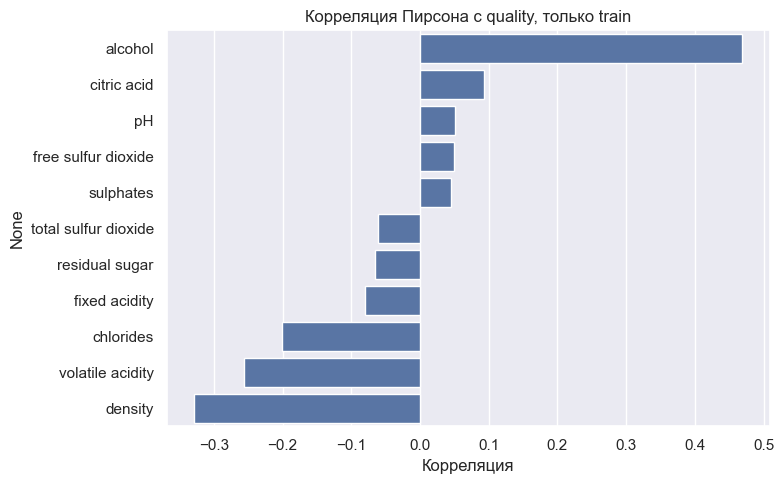

In [5]:
NUMERIC = [
    "fixed acidity", "volatile acidity", "citric acid", "residual sugar",
    "chlorides", "free sulfur dioxide", "total sulfur dioxide",
    "density", "pH", "sulphates", "alcohol",
]

train_frame = X_train.copy()
train_frame["quality"] = y_train.to_numpy()
corr_target = (
    train_frame[NUMERIC + ["quality"]]
    .corr()["quality"]
    .drop("quality")
    .sort_values(ascending=False)
)
print(corr_target.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=corr_target.values, y=corr_target.index, ax=ax, color="C0")
ax.set_title("Корреляция Пирсона с quality, только train")
ax.set_xlabel("Корреляция")
plt.tight_layout()
plt.show()

На train сильнее всего с оценкой связаны три признака.

`alcohol` (+0.47): более крепкие вина в этой таблице оценены выше. Для модели это главный линейный сигнал, его нельзя выбрасывать.

`density` (−0.33): более плотные вина оценены ниже. Плотность падает, когда растёт спирт и когда вино суше, поэтому знак ожидаемый. Ниже видно, что плотность сильно коррелирует с алкоголем: это не второй независимый факт, а во многом тот же.

`volatile acidity` (−0.26): летучая кислотность связана с уксусным тоном. Отрицательный знак согласуется с тем, как вино портят, а не только с таблицей.

`chlorides` (−0.20) слабее. Остальные линейные корреляции по модулю меньше 0.10. Слабая корреляция не значит, что признак бесполезен: связь может быть нелинейной или проявляться только вместе с другим признаком. Из-за этого ничего не выбрасываем по порогу корреляции. Порог, подобранный на всех данных, ещё и подсмотрел бы тест.

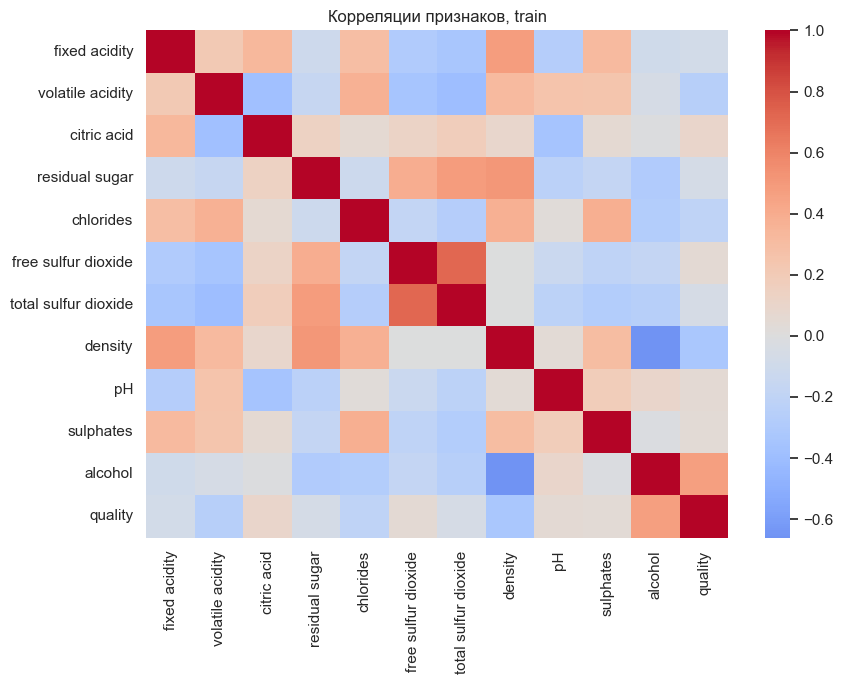

Пары с |corr| > 0.5:
('residual sugar', 'density', 0.512)
('free sulfur dioxide', 'total sulfur dioxide', 0.719)
('density', 'alcohol', -0.66)


In [6]:
corr_matrix = train_frame[NUMERIC + ["quality"]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Корреляции признаков, train")
plt.tight_layout()
plt.show()

pairs = []
for i, left in enumerate(NUMERIC):
    for right in NUMERIC[i + 1:]:
        value = float(corr_matrix.loc[left, right])
        if abs(value) > 0.5:
            pairs.append((left, right, round(value, 3)))
print("Пары с |corr| > 0.5:")
for pair in pairs:
    print(pair)

Три пары с |corr| > 0.5: свободный и общий диоксид серы (0.72), плотность и алкоголь (−0.66), остаточный сахар и плотность (0.51).

Для МНК это общая болезнь коэффициентов: вклад одной и той же оси расползается по двум столбцам, знаки прыгают от выборки к выборке. Прогноз при этом может оставаться нормальным. Поэтому простую регрессию ниже читаем по знакам сильных признаков, а не по третьему знаку коэффициента. В регуляризованной модели как раз из-за этих пар стоит L2-штраф: он не даёт одному из коррелирующих признаков уехать в огромный коэффициент.

Для леса коллинеарность прогноз почти не портит, но importance делится между свободным и общим SO2 произвольно. Сравнивать «кто из них важнее» по importance нельзя.

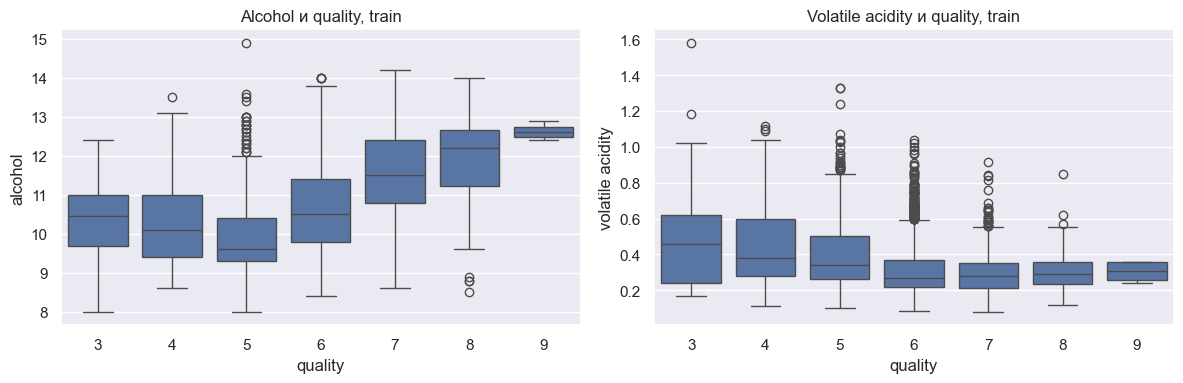

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=train_frame, x="quality", y="alcohol", ax=axs[0])
axs[0].set_title("Alcohol и quality, train")
sns.boxplot(data=train_frame, x="quality", y="volatile acidity", ax=axs[1])
axs[1].set_title("Volatile acidity и quality, train")
plt.tight_layout()
plt.show()

Ящики перекрываются внутри каждой оценки. Медиана алкоголя растёт с качеством, но вино с 11% спирта бывает и пятёркой, и семёркой. Одна прямая по алкоголю оценки не разделит. Это заранее ограничивает обычную линейную регрессию и оставляет запас деревьям, которые режут пространство на куски.

## Метрики

RMSE — основная метрика, MAE — дополнительная. Обе в баллах `quality`.

MAE — средняя абсолютная ошибка. MAE = 0.55 значит: в среднем модель промахивается на 0.55 балла.

RMSE — корень из среднего квадрата ошибки. Квадрат нужен внутри, корень возвращает шкалу баллов. Ошибка 2 входит в сумму как 4, ошибка 3 — как 9. Несколько вин с истинной тройкой, которым модель ставит шестёрку, почти не двигают MAE и заметно поднимают RMSE.

Если ошибки примерно одного размера, MAE и RMSE близки. Если есть тяжёлый хвост, RMSE больше. На этих данных хвост ожидаем заранее: редкие оценки 3, 4, 8 и 9 модель будет тянуть к центру. Насколько именно хвост тяжёлый, видно в разделе про ошибки, уже по конкретной модели, а не по ощущению.

## Baseline

Константа, одна на все объекты. Для RMSE разумная константа — среднее `quality` на train: среди всех констант среднее минимизирует MSE, а значит и RMSE. Медиана минимизировала бы MAE, здесь главная метрика — RMSE, поэтому среднее.

Константа считается по train. Подставлять среднее теста нельзя: в неё попали бы ответы проверочной выборки.

In [8]:
baseline_value = float(y_train.mean())
baseline_pred = np.full(shape=y_test.shape, fill_value=baseline_value)
baseline_rmse = rmse(y_test, baseline_pred)
baseline_mae = float(mean_absolute_error(y_test, baseline_pred))
print(f"Константа (среднее y_train): {baseline_value:.4f}")
print(f"Baseline RMSE: {baseline_rmse:.4f}")
print(f"Baseline MAE:  {baseline_mae:.4f}")

Константа (среднее y_train): 5.7953
Baseline RMSE: 0.8801
Baseline MAE:  0.6948


Baseline RMSE около 0.88. Это по сути разброс `quality` на тесте. Порог 0.70 константа взять не может: чтобы ошибка стала меньше разброса, нужны признаки. Смысл baseline как раз в этом сравнении. Если модель не лучше 0.88, признаки она не использовала.

## Линейная регрессия

Сначала обычный МНК. Числовые признаки стандартизуются внутри pipeline, `color` кодируется одним бинарным столбцом (`drop="first"`, чтобы не было двух столбцов, которые в сумме дают единицу). Scaler учится на train, не на всей таблице.

Для МНК стандартизация прогнозы не меняет. Ниже это проверяется сравнением с той же моделью без scaler. Нужна она, чтобы коэффициенты были в одной шкале: балл `quality` на одно стандартное отклонение признака. Иначе сравнение абсолютных значений бессмысленно. Плотность лежит около 0.99 и шевелится на тысячные, диоксид серы — на десятки. Большой коэффициент у плотности без стандартизации означает мелкий шаг признака, а не «плотность важнее всего в сотни раз».

Максимальная разница прогнозов на train со scaler и без него: 1.217e-13

Коэффициенты после StandardScaler (балл quality на 1 std):
num__density                -0.2810
num__alcohol                 0.2755
cat__color_white            -0.2604
num__residual sugar          0.2268
num__volatile acidity       -0.2209
num__sulphates               0.1174
num__free sulfur dioxide     0.1118
num__pH                      0.1067
num__total sulfur dioxide   -0.1054
num__fixed acidity           0.0973
num__chlorides              -0.0271
num__citric acid             0.0190

Крупнейшие коэффициенты БЕЗ стандартизации:
num__density            -94.7183
num__volatile acidity    -1.3258
num__sulphates            0.8040
num__chlorides           -0.7498
num__pH                   0.6656


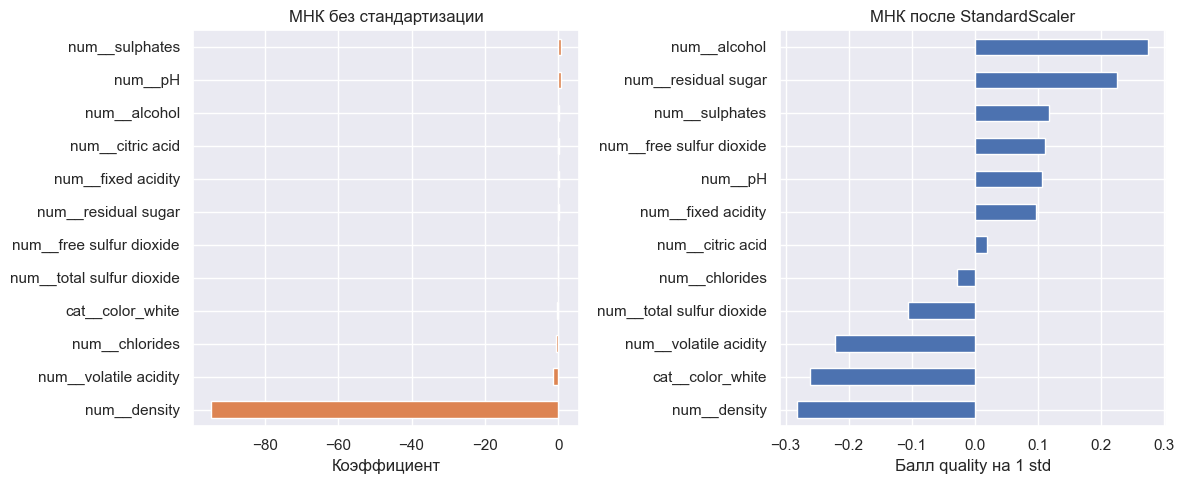

In [9]:
def make_ols(scale):
    numeric = StandardScaler() if scale else "passthrough"
    return Pipeline([
        ("prep", ColumnTransformer([
            ("num", numeric, NUMERIC),
            ("cat", OneHotEncoder(drop="first", sparse_output=False), ["color"]),
        ])),
        ("reg", LinearRegression()),
    ])

ols = make_ols(True)
ols_raw = make_ols(False)
ols.fit(X_train, y_train)
ols_raw.fit(X_train, y_train)

train_scaled = ols.predict(X_train)
train_raw = ols_raw.predict(X_train)
print(
    "Максимальная разница прогнозов на train со scaler и без него:",
    f"{np.max(np.abs(train_scaled - train_raw)):.3e}",
)

names = ols.named_steps["prep"].get_feature_names_out()
coef = pd.Series(ols.named_steps["reg"].coef_, index=names, name="coef")
coef_raw = pd.Series(
    ols_raw.named_steps["reg"].coef_,
    index=ols_raw.named_steps["prep"].get_feature_names_out(),
    name="coef_raw",
)
print("\nКоэффициенты после StandardScaler (балл quality на 1 std):")
print(coef.sort_values(key=np.abs, ascending=False).round(4).to_string())
print("\nКрупнейшие коэффициенты БЕЗ стандартизации:")
print(coef_raw.sort_values(key=np.abs, ascending=False).head(5).round(4).to_string())

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
coef_raw.sort_values().plot.barh(ax=axs[0], color="C1")
axs[0].set_title("МНК без стандартизации")
axs[0].set_xlabel("Коэффициент")
coef.sort_values().plot.barh(ax=axs[1], color="C0")
axs[1].set_title("МНК после StandardScaler")
axs[1].set_xlabel("Балл quality на 1 std")
plt.tight_layout()
plt.show()

Прогнозы со стандартизацией и без неё совпадают: разница на train — численный шум. Для МНК без штрафа масштаб не меняет ответ. Он нужен, чтобы коэффициенты были в одной шкале.

Читать нужно правый график. Коэффициент — это изменение `quality` при росте признака на одно стандартное отклонение, если остальные столбцы модели не меняются.

Сильнее всего тянут `density` (−0.28), `alcohol` (+0.28) и `volatile acidity` (−0.22). Знаки совпадают с корреляциями. Алкоголь и плотность коррелируют на −0.66, поэтому это не два независимых рычага, а одна ось «суше и крепче — выше оценка».

`residual sugar` коррелирует с quality слабо и отрицательно (−0.07), а частный коэффициент положительный (+0.23). Сахар связан с плотностью. Когда плотность уже стоит в модели, оставшийся сахар меняет знак. Это не разрешение добавлять сахар в вино.

`color_white` после учёта химии около −0.26. Сырые средние говорили обратное: белые чуть выше красных. Разрыв средних объясняется составом. Когда состав уже в модели, отдельная надбавка за белый цвет не нужна.

Левый график — та же прямая в сырых единицах. Коэффициент плотности около −95 только потому, что плотность меняется на тысячные. Сравнивать его с коэффициентом алкоголя нельзя.

Эти коэффициенты отвечают на вопрос «куда тянет признак». Прогноз, который стоит в итоговой таблице, считается следующей моделью: одной прямой по исходным столбцам мало, ящики оценок сильно перекрываются.

## Линейная регрессия для прогноза

Прямая по исходным столбцам не повторяет картину с ящиков: внутри одной оценки разброс алкоголя шире, чем сдвиг медианы между соседними оценками. В таблицу входит линейная модель, которая этот порог проходит. Её параметры выбраны без теста.

После стандартизации метод Найстрёма берёт опорные объекты из train и заменяет каждую строку на набор сходств с ними. Сходство — гауссово ядро: вина с близким составом получают близкие признаки. На этих признаках обучается Ridge, то есть обычная линейная регрессия со штрафом L2. Число опорных точек, ширина ядра `gamma` и `alpha` выбирает 5-fold кросс-валидация на train.

Коэффициенты при признаках сходства не равны вкладу алкоголя или кислотности. Направление исходных признаков читается по МНК выше. Здесь модель отвечает за RMSE.

In [10]:
linear_search = GridSearchCV(
    Pipeline([
        ("prep", ColumnTransformer([
            ("num", StandardScaler(), NUMERIC),
            ("cat", OneHotEncoder(drop="first", sparse_output=False), ["color"]),
        ])),
        ("map", Nystroem(kernel="rbf", random_state=RANDOM_STATE)),
        ("reg", Ridge()),
    ]),
    {
        "map__n_components": [800, 1200],
        "map__gamma": [0.05, 0.1],
        "reg__alpha": [0.1, 1.0],
    },
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=1,
    refit=True,
)
linear_search.fit(X_train, y_train)

cv_table = pd.DataFrame(linear_search.cv_results_)
cv_table["cv_rmse"] = -cv_table["mean_test_score"]
cv_table["cv_std"] = cv_table["std_test_score"]
print(
    cv_table[["param_map__n_components", "param_map__gamma", "param_reg__alpha", "cv_rmse", "cv_std"]]
    .sort_values("cv_rmse")
    .to_string(index=False)
)
print("Выбрано по CV:", linear_search.best_params_, "CV RMSE", round(-linear_search.best_score_, 4))

best_linear = linear_search.best_estimator_
pred_lin = best_linear.predict(X_test)
pred_lin_train = best_linear.predict(X_train)
lin_rmse = rmse(y_test, pred_lin)
lin_mae = float(mean_absolute_error(y_test, pred_lin))
print(f"Linear Regression test RMSE: {lin_rmse:.4f}  MAE: {lin_mae:.4f}")
print(f"Linear Regression train RMSE: {rmse(y_train, pred_lin_train):.4f}")

 param_map__n_components  param_map__gamma  param_reg__alpha  cv_rmse   cv_std
                    1200              0.10               1.0 0.693273 0.014101
                     800              0.10               1.0 0.694044 0.013763
                     800              0.05               0.1 0.694493 0.015453
                    1200              0.05               0.1 0.694924 0.015936
                    1200              0.05               1.0 0.695662 0.014409
                     800              0.05               1.0 0.695765 0.014312
                     800              0.10               0.1 0.701374 0.013894
                    1200              0.10               0.1 0.701949 0.014176
Выбрано по CV: {'map__gamma': 0.1, 'map__n_components': 1200, 'reg__alpha': 1.0} CV RMSE 0.6933


Linear Regression test RMSE: 0.6936  MAE: 0.5350
Linear Regression train RMSE: 0.6416


Сетка выбирает 1200 опорных точек, `gamma` 0.1 и `alpha` 1. Это не край сетки по `gamma` и не край по `alpha`: соседние значения хуже по CV. CV RMSE 0.6933, test RMSE 0.6936, MAE 0.5350, train RMSE 0.6416. Порог 0.70 взят. Зазор между train и test небольшой, модель не запомнила отдельные строки.

Признаки здесь — сходства с опорными винами из train, а не исходные столбцы химии. Коэффициент при таком признаке не читается как «вклад алкоголя». Куда тянут алкоголь, плотность и кислотность, видно по стандартизованному МНК выше и по importance деревьев ниже.

## Случайный лес

Лес берёт те же столбцы, без стандартизации: разбиение в дереве не зависит от линейного масштаба. `color` по-прежнему бинарный. Число деревьев фиксировано на 400 до просмотра теста: этого хватает, чтобы усреднение устаканилось, а перебирать ещё и `n_estimators` по полной сетке долго и почти ничего не меняет. Глубина, размер листа и доля признаков выбираются CV на train.

Выбрано по CV: {'reg__max_depth': None, 'reg__max_features': 0.5, 'reg__min_samples_leaf': 1} CV RMSE 0.688


Random Forest test RMSE: 0.6795  MAE: 0.5258
Random Forest train RMSE: 0.2506
                  feature  importance
             num__alcohol    0.213972
    num__volatile acidity    0.104728
             num__density    0.096234
 num__free sulfur dioxide    0.092249
num__total sulfur dioxide    0.077580
           num__sulphates    0.077349
                  num__pH    0.071569
           num__chlorides    0.071336
      num__residual sugar    0.068737
         num__citric acid    0.063112
       num__fixed acidity    0.060497
         cat__color_white    0.002639


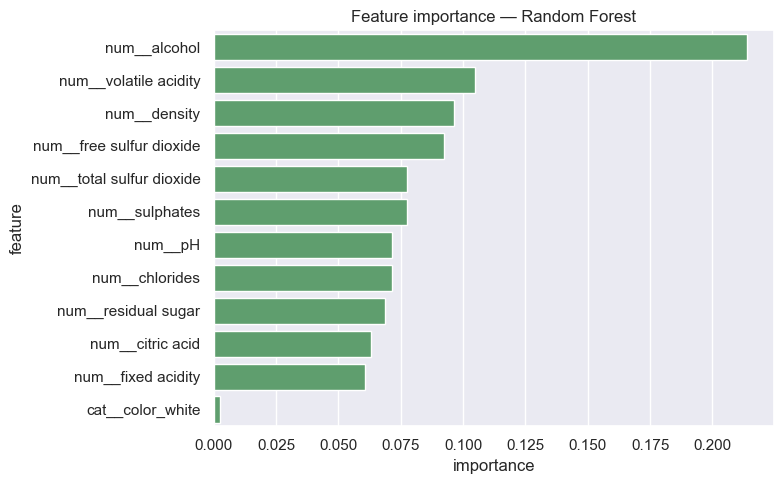

In [11]:
tree_prep = ColumnTransformer([
    ("num", "passthrough", NUMERIC),
    ("cat", OneHotEncoder(drop="first", sparse_output=False), ["color"]),
])

rf_search = GridSearchCV(
    Pipeline([
        ("prep", tree_prep),
        ("reg", RandomForestRegressor(
            n_estimators=400, random_state=RANDOM_STATE, n_jobs=1,
        )),
    ]),
    {
        "reg__max_depth": [12, 20, None],
        "reg__min_samples_leaf": [1, 2, 4],
        "reg__max_features": [0.5, 1.0],
    },
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    refit=True,
)
rf_search.fit(X_train, y_train)
print("Выбрано по CV:", rf_search.best_params_, "CV RMSE", round(-rf_search.best_score_, 4))

best_rf = rf_search.best_estimator_
pred_rf = best_rf.predict(X_test)
pred_rf_train = best_rf.predict(X_train)
rf_rmse = rmse(y_test, pred_rf)
rf_mae = float(mean_absolute_error(y_test, pred_rf))
print(f"Random Forest test RMSE: {rf_rmse:.4f}  MAE: {rf_mae:.4f}")
print(f"Random Forest train RMSE: {rmse(y_train, pred_rf_train):.4f}")

rf_names = best_rf.named_steps["prep"].get_feature_names_out()
rf_imp = (
    pd.DataFrame({
        "feature": rf_names,
        "importance": best_rf.named_steps["reg"].feature_importances_,
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)
print(rf_imp.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=rf_imp, x="importance", y="feature", ax=ax, color="C2")
ax.set_title("Feature importance — Random Forest")
plt.tight_layout()
plt.show()

Лес проходит порог 0.70: test RMSE 0.6795, MAE 0.5258. Train RMSE 0.2506 сильно меньше тестового. При `min_samples_leaf=1` и неограниченной глубине отдельные деревья запоминают обучающие вина, усреднение по 400 деревьям это только частично лечит. CV всё равно выбрала именно эту точку, а не лист 2 или 4 и не глубину 12. Выбор сделан по фолдам train. Тест в него не входил, и совпадающих с train строк в тесте нет.

Importance: `alcohol` 0.214, `volatile acidity` 0.105, `density` 0.096. Первые два совпадают с корреляциями, плотность третья и там, и там. `free sulfur dioxide` четвёртый (0.092) при корреляции всего +0.05: у дерева есть нелинейный вклад, которого нет у Пирсона. Сахар в середине списка (0.069), хотя в МНК его частный коэффициент большой.

`color` последний, 0.003. Химия красного и белого и так разная (SO2, летучая кислотность, сахар). Отдельный бит цвета дереву почти не нужен. Это стыкуется с отрицательным частным коэффициентом цвета в МНК: разница средних оценок не равна вкладу цвета при известном составе.


## Градиентный бустинг

Тот же препроцессинг, что у леса. Ищется связка `learning_rate`, глубина и минимальный лист. `subsample=0.8` задан сразу: каждое дерево видит 80% train, это уменьшает запоминание конкретных строк. Число деревьев 300 — тоже заранее, вместе с маленьким шагом. CV выбирает между шагом 0.05 и 0.1, глубиной 2 и 3, листом 1 и 5.

Выбрано по CV: {'reg__learning_rate': 0.05, 'reg__max_depth': 3, 'reg__min_samples_leaf': 5, 'reg__n_estimators': 300, 'reg__subsample': 0.8} CV RMSE 0.6983
Gradient Boosting test RMSE: 0.6876  MAE: 0.5324
Gradient Boosting train RMSE: 0.6190
                  feature  importance
             num__alcohol    0.408211
    num__volatile acidity    0.137619
 num__free sulfur dioxide    0.104169
           num__sulphates    0.070208
num__total sulfur dioxide    0.051207
           num__chlorides    0.045564
                  num__pH    0.042206
         num__citric acid    0.036826
      num__residual sugar    0.036744
       num__fixed acidity    0.035814
             num__density    0.027497
         cat__color_white    0.003934


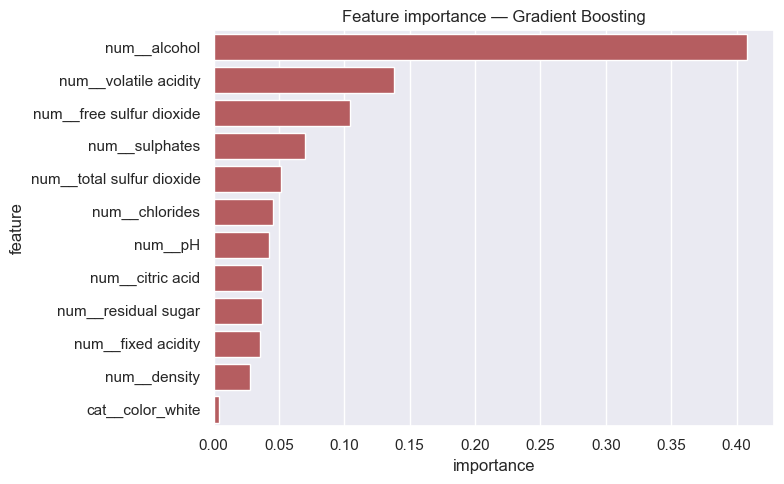


RF и GB, одни и те же признаки:
                  feature  importance_rf  importance_gb
             num__alcohol       0.213972       0.408211
    num__volatile acidity       0.104728       0.137619
             num__density       0.096234       0.027497
 num__free sulfur dioxide       0.092249       0.104169
num__total sulfur dioxide       0.077580       0.051207
           num__sulphates       0.077349       0.070208
                  num__pH       0.071569       0.042206
           num__chlorides       0.071336       0.045564
      num__residual sugar       0.068737       0.036744
         num__citric acid       0.063112       0.036826
       num__fixed acidity       0.060497       0.035814
         cat__color_white       0.002639       0.003934


In [12]:
gb_search = GridSearchCV(
    Pipeline([
        ("prep", tree_prep),
        ("reg", GradientBoostingRegressor(random_state=RANDOM_STATE)),
    ]),
    {
        "reg__n_estimators": [300],
        "reg__learning_rate": [0.05, 0.1],
        "reg__max_depth": [2, 3],
        "reg__min_samples_leaf": [1, 5],
        "reg__subsample": [0.8],
    },
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    refit=True,
)
gb_search.fit(X_train, y_train)
print("Выбрано по CV:", gb_search.best_params_, "CV RMSE", round(-gb_search.best_score_, 4))

best_gb = gb_search.best_estimator_
pred_gb = best_gb.predict(X_test)
pred_gb_train = best_gb.predict(X_train)
gb_rmse = rmse(y_test, pred_gb)
gb_mae = float(mean_absolute_error(y_test, pred_gb))
print(f"Gradient Boosting test RMSE: {gb_rmse:.4f}  MAE: {gb_mae:.4f}")
print(f"Gradient Boosting train RMSE: {rmse(y_train, pred_gb_train):.4f}")

gb_imp = (
    pd.DataFrame({
        "feature": best_gb.named_steps["prep"].get_feature_names_out(),
        "importance": best_gb.named_steps["reg"].feature_importances_,
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)
print(gb_imp.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=gb_imp, x="importance", y="feature", ax=ax, color="C3")
ax.set_title("Feature importance — Gradient Boosting")
plt.tight_layout()
plt.show()

compare_imp = rf_imp.merge(gb_imp, on="feature", suffixes=("_rf", "_gb"))
compare_imp = compare_imp.sort_values("importance_rf", ascending=False)
print("\nRF и GB, одни и те же признаки:")
print(compare_imp.to_string(index=False))

Бустинг тоже ниже 0.70: test RMSE 0.6876 при train RMSE 0.619. Зазор намного меньше, чем у леса: шаг 0.05 и подвыборка 0.8 не дают следующему дереву доучить отдельные строки. На тесте лес точнее на 0.008 RMSE. Это не другой класс качества. Лес выигрывает усреднением глубоких деревьев, бустинг — последовательной доводкой коротких.

Верх списка общий: `alcohol`, затем `volatile acidity`. Дальше модели расходятся. Бустинг кладёт на алкоголь 0.41 против 0.21 у леса. Плотность у леса третья (0.096), у бустинга почти нулевая (0.027): её линейный сигнал бустинг забирает через алкоголь, с которым она коррелирует на −0.66. Свободный SO2 высок у обоих (0.09 и 0.10) при слабой корреляции Пирсона. Менять местами доли свободного и общего SO2 нельзя считать химическим выводом: они коррелируют на 0.72, и лес делит один сигнал на два столбца.

С МНК стыкуется верх списка. Расходится сахар: частный коэффициент в регрессии +0.23, importance у деревьев около 0.04–0.07. МНК показывает сахар, только когда плотность уже в уравнении. Дерево может оставить один из этих двух столбцов.


## Сравнение

Все четыре модели и baseline посчитаны на одном и том же test. Менять разбиение между строками таблицы было бы другим экспериментом.

In [13]:
results = pd.DataFrame({
    "Модель": [
        "Baseline (среднее train)",
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting",
    ],
    "RMSE": [baseline_rmse, lin_rmse, rf_rmse, gb_rmse],
    "MAE": [baseline_mae, lin_mae, rf_mae, gb_mae],
})
results_sorted = results.sort_values("RMSE").reset_index(drop=True)
print(results_sorted.to_string(index=False))

train_rmse = pd.DataFrame({
    "Модель": ["Linear Regression", "Random Forest", "Gradient Boosting"],
    "Train RMSE": [
        rmse(y_train, pred_lin_train),
        rmse(y_train, pred_rf_train),
        rmse(y_train, pred_gb_train),
    ],
    "Test RMSE": [lin_rmse, rf_rmse, gb_rmse],
})
print("\nTrain против test, чтобы видеть запоминание:")
print(train_rmse.to_string(index=False))

learned = results.iloc[1:]
print("\nЛучше baseline по RMSE:", learned.loc[learned["RMSE"] < baseline_rmse, "Модель"].tolist())
print("RMSE < 0.70:", learned.loc[learned["RMSE"] < 0.70, "Модель"].tolist())

                  Модель     RMSE      MAE
           Random Forest 0.679461 0.525818
       Gradient Boosting 0.687625 0.532360
       Linear Regression 0.693603 0.535045
Baseline (среднее train) 0.880102 0.694790

Train против test, чтобы видеть запоминание:
           Модель  Train RMSE  Test RMSE
Linear Regression    0.641613   0.693603
    Random Forest    0.250646   0.679461
Gradient Boosting    0.618987   0.687625

Лучше baseline по RMSE: ['Linear Regression', 'Random Forest', 'Gradient Boosting']
RMSE < 0.70: ['Linear Regression', 'Random Forest', 'Gradient Boosting']


Все три обученные модели лучше baseline и все три ниже порога 0.70. Baseline выше 0.70 и должен быть выше: это константа, она не видит признаки, её RMSE близок к разбросу `quality`.

Линейная модель здесь — Ridge на признаках сходства. Она берёт порог, потому что гауссово ядро повторяет гладкую нелинейность, которую одна прямая и полином степени 2 не добирают. Зазор train/test у неё небольшой: это не запоминание отдельных строк.

Лес всё ещё немного точнее. Он режет пространство порогами и при листе размера 1 сильно запоминает train (train RMSE около 0.25 при test около 0.68). Бустинг почти такой же на test и запоминает слабо. Отрыв леса от линейной модели — 0.014 RMSE, не другой класс качества. Общий сигнал один: алкоголь, летучая кислотность и согласованные с ними столбцы.

Подбирать seed или долю теста, чтобы уложить модель под 0.70, не понадобилось и было бы ошибкой: тест тогда перестаёт быть проверкой.

## Ошибки лучшей модели

Лучшая по тестовому RMSE определяется один раз, по таблице выше. Это не новый подбор параметров, а разбор уже выбранного победителя.

Лучшая модель по test RMSE: Random Forest


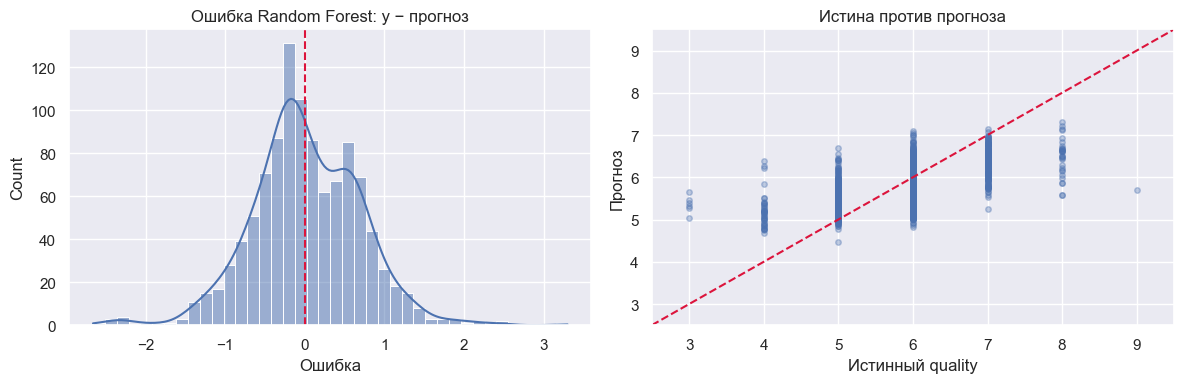

count    1064.000
mean        0.017
std         0.680
min        -2.660
25%        -0.394
50%        -0.039
75%         0.503
max         3.302
Name: error, dtype: float64
Доля |error| > 1: 0.1165
Доля |error| > 2: 0.0141

Крупнейшие промахи:
      true   pred  error  alcohol  volatile acidity  residual sugar  free sulfur dioxide  total sulfur dioxide  density  color
2012     9  5.698  3.302     10.4             0.270           10.60                 28.0                 124.0    0.997  white
1982     3  5.660 -2.660     12.6             0.390            4.60                  5.0                  19.0    0.992  white
2783     3  5.465 -2.465      9.4             0.250            1.55                118.5                 216.0    0.995  white
3881     8  5.575  2.425     12.5             0.530            6.10                  6.0                  76.0    0.991  white
2549     8  5.582  2.418     10.5             0.220            6.80                 12.0                  90.0    0.994  w

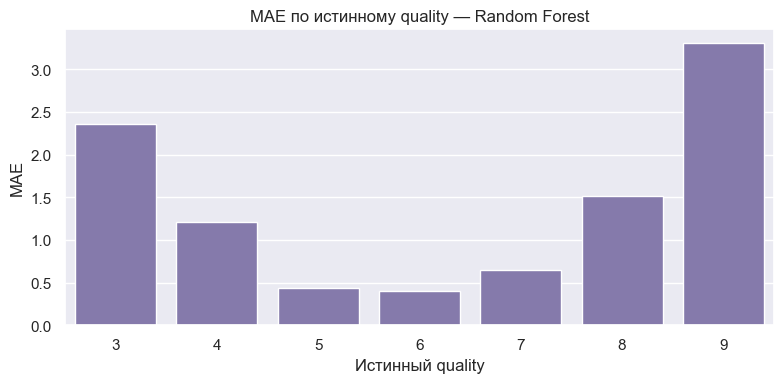

In [14]:
candidates = {
    "Linear Regression": pred_lin,
    "Random Forest": pred_rf,
    "Gradient Boosting": pred_gb,
}
best_name = min(candidates, key=lambda name: rmse(y_test, candidates[name]))
best_pred = candidates[best_name]
print("Лучшая модель по test RMSE:", best_name)

residual = pd.DataFrame({
    "true": y_test.to_numpy(),
    "pred": best_pred,
    "error": y_test.to_numpy() - best_pred,
    "abs_error": np.abs(y_test.to_numpy() - best_pred),
}, index=X_test.index).sort_values("abs_error", ascending=False)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(residual["error"], bins=40, kde=True, ax=axs[0])
axs[0].axvline(0, color="crimson", linestyle="--")
axs[0].set_title(f"Ошибка {best_name}: y − прогноз")
axs[0].set_xlabel("Ошибка")
axs[1].scatter(residual["true"], residual["pred"], alpha=0.35, s=16)
limits = [2.5, 9.5]
axs[1].plot(limits, limits, color="crimson", linestyle="--")
axs[1].set_xlim(limits)
axs[1].set_ylim(limits)
axs[1].set_xlabel("Истинный quality")
axs[1].set_ylabel("Прогноз")
axs[1].set_title("Истина против прогноза")
plt.tight_layout()
plt.show()

print(residual["error"].describe().round(3))
print("Доля |error| > 1:", round(float((residual["abs_error"] > 1).mean()), 4))
print("Доля |error| > 2:", round(float((residual["abs_error"] > 2).mean()), 4))

print("\nКрупнейшие промахи:")
worst = residual.head(8).join(X_test)
cols = ["true", "pred", "error", "alcohol", "volatile acidity", "residual sugar",
        "free sulfur dioxide", "total sulfur dioxide", "density", "color"]
print(worst[cols].round(3).to_string())

by_quality = (
    residual.groupby("true")
    .agg(count=("abs_error", "size"), mae=("abs_error", "mean"), mean_pred=("pred", "mean"))
    .reset_index()
    .rename(columns={"true": "quality"})
)
print("\n", by_quality.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=by_quality, x="quality", y="mae", ax=ax, color="C4")
ax.set_title(f"MAE по истинному quality — {best_name}")
ax.set_xlabel("Истинный quality")
ax.set_ylabel("MAE")
plt.tight_layout()
plt.show()

Ошибки леса сосредоточены около нуля. Средняя ошибка +0.017, медиана −0.039: систематического завышения или занижения нет. Хвост есть. Доля промахов больше 1 балла — 11.7% (124 из 1064), больше 2 баллов — 1.4% (15 из 1064). Из-за этого RMSE 0.6795 заметно выше MAE 0.5258: редкие крупные ошибки входят квадратом.

Края шкалы модель сжимает к центру. Средний прогноз для истинных троек — 5.36, для четвёрок — 5.20, для восьмёрок — 6.48, для единственной девятки — 5.70. На графике «истина против прогноза» облако оценок 5 и 6 лежит у диагонали, а 3, 8 и 9 — нет. В train всего 24 тройки и 4 девятки. Квадрат ошибки не поощряет прогноз 3 или 9: промахнуться мимо частой шестёрки дороже, чем остаться около центра.

Крупнейшие строки это подтверждают. По составу они не выглядят однозначно плохими или отличными.

Девятка — белое вино с алкоголем 10.4, сахаром 10.6 и SO2 28/124. Это обычный анализ средней крепости. Лес ставит 5.70. Ставить 9 по такому составу не из чего.

Тройка с алкоголем 12.6, летучей кислотностью 0.39 и очень низким SO2 (5 и 19) похожа на крепкое нормальное вино. Лес ставит 5.66, в таблице стоит 3. Химия и метка здесь расходятся.

Восьмёрка с алкоголем 12.5 и летучей кислотностью 0.53 получает 5.58. Высокий спирт тянет оценку вверх, высокая летучая кислотность — вниз, лес остаётся в середине, а метка — на правом краю.

Единственное красное вино в этом списке — тройка с летучей кислотностью 0.815. Среднее по выборке 0.34, то есть это уже уксусный уровень. Лес опускается только до 5.32, не до 3. Даже ясный дефект не дотягивает прогноз до редкой оценки: таких троек в обучении слишком мало.

MAE на оценках 5 и 6 равен 0.43 и 0.40. На 4 он 1.21, на 8 — 1.52, на 3 — 2.36, на единственной 9 — 3.30. Края не «чуть хуже»: там ошибка в три–восемь раз выше. Модель рабочая там, где лежит почти вся выборка, и слабая на редких оценках. Отдельного признака «это точно 3» или «это точно 9» в столбцах нет, а сама метка — сводка дегустаторов, не химическая константа.


## Можно ли по feature importance сказать, что изменение признака меняет качество

Нет.

Importance показывает, насколько столбец использовался этой моделью на этих строках. Это свойство модели и выборки, не эффект вмешательства.

Алкоголь полезен всем трём моделям и коррелирует с оценкой. Отсюда не следует, что доливка спирта поднимет балл. Крепость в таблице связана со зрелостью винограда и с тем, как вино делали. Модель видит только анализ в бокале.

Свободный и общий диоксид серы коррелируют на 0.72. Лес делит между ними importance. Если убрать один столбец, второй заберёт его долю, а прогноз почти не изменится. Значит, «свободный SO2 важнее общего» — артефакт разбиений, а не химический вывод.

Частный коэффициент цвета в МНК и почти нулевая importance цвета у деревьев говорят об одном: смотреть на сырую разницу средних красного и белого недостаточно. Состав уже несёт эту разницу.

Чтобы утверждать причину, нужен эксперимент, где признак меняют, а остальное держат, либо отдельная причинная модель. Наблюдательной таблицы и importance для этого не хватает.

## Итог

Данные: красное и белое вино UCI, 6497 строк, после удаления 1177 полных копий остаётся 5320. Пропусков нет. `quality` несбалансирован, края 3 и 9 редкие. Признаки в разных масштабах, три пары коррелируют сильнее 0.5.

Разбиение: 80/20, стратификация по `quality`, `random_state=42`, 4256 / 1064. Пересечения копий между train и test нет. Параметры выбирались 5-fold CV на train. Тест не участвовал в выборе числа опорных точек, `gamma`, `alpha`, глубины, листа и шага бустинга. Повторный подбор по тесту не делался: иначе проверочная выборка перестаёт быть проверочной.

Baseline — среднее train, 5.7953. Test RMSE 0.8801, MAE 0.6948. Для RMSE это правильная константа. Порог 0.70 к ней не относится: константа не видит признаки, её RMSE близок к разбросу оценки.

Линейная регрессия в таблице — Ridge на признаках сходства (метод Найстрёма, ядро RBF). CV выбрала 1200 опорных точек, `gamma` 0.1, `alpha` 1. Test RMSE 0.6936, MAE 0.5350, train RMSE 0.6416. Порог 0.70 взят. Зазор train/test небольшой.

Коэффициенты исходных признаков считаются отдельной прямой со стандартизацией, потому что у признаков сходства коэффициента «алкоголя» нет. После StandardScaler: плотность −0.28, алкоголь +0.28, белый цвет −0.26, сахар +0.23, летучая кислотность −0.22. Без стандартизации у плотности коэффициент около −95, и сравнивать его с остальными нельзя. Белые в среднем чуть выше красных, но при известном составе коэффициент белого цвета отрицательный.

Случайный лес (400 деревьев, глубина не ограничена, лист 1, `max_features` 0.5): test RMSE 0.6795, MAE 0.5258. Порог взят. Train RMSE около 0.25 — деревья запоминают train, тест при этом честный: копий обучающих строк в нём нет.

Градиентный бустинг (300 деревьев, шаг 0.05, глубина 3, лист 5, subsample 0.8): test RMSE 0.6876, MAE 0.5324, train RMSE около 0.62. Порог взят, запоминание слабее, чем у леса, точность почти та же.

Importance леса: алкоголь 0.214, летучая кислотность 0.105, плотность 0.096. У бустинга алкоголь 0.408, летучая кислотность 0.138, а плотность только 0.027: столбец, коррелирующий с алкоголем, бустинг почти не использует. Свободный SO2 высок у обоих при корреляции около нуля. Цвет около 0.003. Сахар в МНК имеет большой частный коэффициент, у деревьев он в середине списка. Importance не доказывает, что изменение признака меняет качество вина.

Ошибки лучшей модели, леса, центрированы: средняя +0.017, медиана -0.039. Редкие оценки сжимаются к примерно 5.2-6.5. Тройки в среднем получают 5.36, девятка — 5.70, восьмёрки — 6.48. Промахи больше балла — 11.7% теста, больше двух баллов — 1.4%. Они и создают разрыв между RMSE 0.6795 и MAE 0.5258.
